In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint
import math as m


In [2]:
T_m = 0.08
k_e = 0.5
n = 15001
t = np.linspace(0,15,n)
B = 0.19
r = 0.028


In [3]:
def motor(state,t,u):
    speed, angle = state
    state_dt = [-speed/T_m + u/ (T_m * k_e), speed ]
    return state_dt


In [4]:
state_l = [0 , 0]
state_r = [0 , 0]
control_l = np.zeros(n)
control_r = np.zeros(n)
theta_l = np.zeros(n)
theta_r = np.zeros(n)
x = np.zeros(n)
y = np.zeros(n)
path = np.zeros(n)
phi = np.zeros(n)


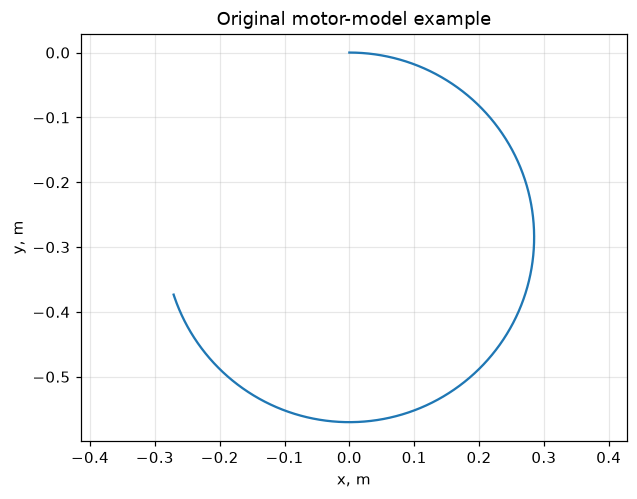

[ 0.00000000e+00  0.00000000e+00  5.22791388e-07 ... -2.70961319e-01
 -2.70987384e-01 -2.71013426e-01]
[ 0.00000000e+00  0.00000000e+00 -9.59009006e-13 ... -3.73473893e-01
 -3.73394040e-01 -3.73314178e-01]


In [5]:
for i in range(1,n):

    path[i] = (theta_r[i-1] + theta_l[i-1]) * r / 2
    phi[i] = (theta_r[i-1] - theta_l[i-1]) * r / B
    x[i] = x[i-1] + (path[i]-path[i-1]) * m.cos(phi[i])
    y[i] = y[i-1] + (path[i]-path[i-1]) * m.sin(phi[i])

    control_l [i] = 2
    control_r [i] = 1

    motor_l = odeint(motor, state_l,[t[i-1],t[i]],args=(control_l [i],))
    state_l = motor_l[1,:]
    theta_l[i] = motor_l[1,1]
    motor_r = odeint(motor, state_r,[t[i-1],t[i]],args=(control_r [i],))
    state_r = motor_r[1,:]
    theta_r[i] = motor_r[1,1]

plt.plot(x, y)
print(x)
print(y)
plt.axis('equal')
plt.grid(True, alpha=0.3)
plt.xlabel('x, m'); plt.ylabel('y, m')
plt.title('Original motor-model example')
plt.show()


In [6]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

if not Path('odometry_data_sim.txt').exists() or not Path('odometry_data_real.txt').exists():
    from google.colab import files
    uploaded = files.upload()

x_s, y_s, t_s = np.loadtxt('odometry_data_sim.txt', delimiter=',', unpack=True)
x_r, y_r, t_r = np.loadtxt('odometry_data_real.txt', delimiter=',', unpack=True)

assert np.isfinite([x_s, y_s, t_s]).all()
assert np.isfinite([x_r, y_r, t_r]).all()
assert np.all(np.diff(t_s) > 0) and np.all(np.diff(t_r) > 0)

print('Simulator samples:', len(x_s))
print('Physical robot samples:', len(x_r))


Simulator samples: 5688
Physical robot samples: 2422


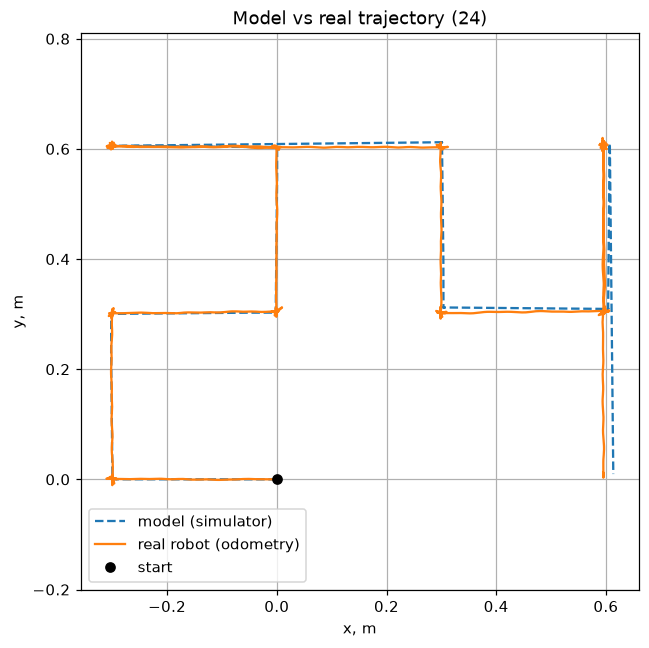

In [7]:
plt.figure(figsize=(6, 6))
plt.plot(x_s, y_s, '--', label='model (simulator)')
plt.plot(x_r, y_r, label='real robot (odometry)')
plt.plot(0, 0, 'ko', label='start')
plt.axis('equal'); plt.grid(True); plt.legend(loc='lower left')
plt.xlabel('x, m'); plt.ylabel('y, m')
plt.title('Model vs real trajectory (24)')
plt.tight_layout()
plt.show()


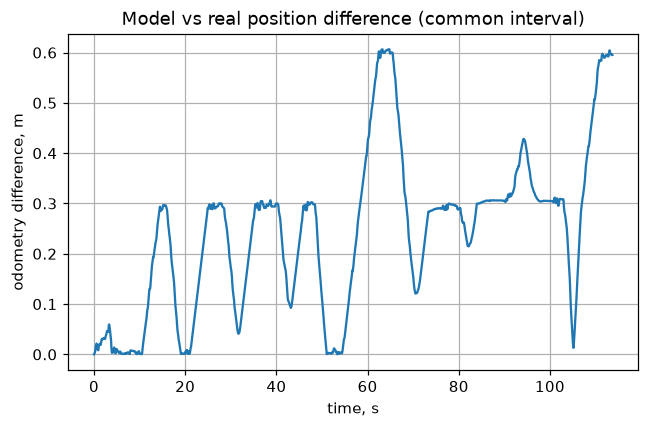

Final odometry endpoint difference: 0.018250 m (1.825 cm)
Max time-aligned difference: 0.607 m
Mean time-aligned difference: 0.243 m
Time-aligned RMSE: 0.290 m
Simulator path length: 3.706 m
Physical odometry path length: 5.623 m
Simulator recorded duration: 113.720 s
Physical recorded duration: 128.760 s


In [8]:
t_s_rel = (t_s - t_s[0]) / 1000
t_r_rel = (t_r - t_r[0]) / 1000
common = t_r_rel <= t_s_rel[-1]
xs_i = np.interp(t_r_rel[common], t_s_rel, x_s)
ys_i = np.interp(t_r_rel[common], t_s_rel, y_s)
err = np.hypot(x_r[common] - xs_i, y_r[common] - ys_i)

plt.figure(figsize=(6, 4))
plt.plot(t_r_rel[common], err)
plt.xlabel('time, s'); plt.ylabel('odometry difference, m'); plt.grid(True)
plt.title('Model vs real position difference (common interval)')
plt.tight_layout()
plt.show()


final_difference = np.hypot(x_r[-1] - x_s[-1], y_r[-1] - y_s[-1])
length_s = np.hypot(np.diff(x_s), np.diff(y_s)).sum()
length_r = np.hypot(np.diff(x_r), np.diff(y_r)).sum()
print(f'Final odometry endpoint difference: {final_difference:.6f} m ({final_difference*100:.3f} cm)')
print(f'Max time-aligned difference: {err.max():.3f} m')
print(f'Mean time-aligned difference: {err.mean():.3f} m')
print(f'Time-aligned RMSE: {np.sqrt(np.mean(err**2)):.3f} m')
print(f'Simulator path length: {length_s:.3f} m')
print(f'Physical odometry path length: {length_r:.3f} m')
print(f'Simulator recorded duration: {t_s_rel[-1]:.3f} s')
print(f'Physical recorded duration: {t_r_rel[-1]:.3f} s')
